In [7]:
import pickle

import matplotlib.pyplot as plt

# import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import train_test_split


In [21]:
from pathlib import Path

Path.cwd().parent.parent

PosixPath('/home/pamya/Python/ML_Projects/RetainAI')

In [2]:
project_dir = '/home/pamya/Python/ML_Projects/RetainAI'  # Adjust this path as needed

Dataset Shape: (50000, 25)

First 5 rows:

Missing Values per Feature:
Age                              2495
Gender                              0
Country                             0
City                                0
Membership_Years                    0
Login_Frequency                     0
Session_Duration_Avg             3399
Pages_Per_Session                3000
Cart_Abandonment_Rate               0
Wishlist_Items                   4000
Total_Purchases                     0
Average_Order_Value                 0
Days_Since_Last_Purchase         3000
Discount_Usage_Rate              3500
Returns_Rate                     4491
Email_Open_Rate                  2528
Customer_Service_Calls            168
Product_Reviews_Written          3500
Social_Media_Engagement_Score    6000
Mobile_App_Usage                 5000
Payment_Method_Diversity         2500
Lifetime_Value                      0
Credit_Balance                   5500
Churned                             0
Signup_Quarter   

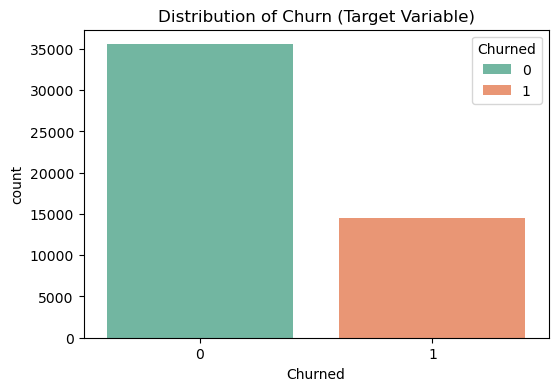

In [4]:
# Load the dataset (ensure the CSV is in your project directory)
df = pd.read_csv(f'{project_dir}/data/raw/eCommerce_dataset.csv')

# 1. Basic Inspection
print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
df.sample(5)

# 2. Check for Missing Values
print("\nMissing Values per Feature:")
print(df.isnull().sum())

# 3. Target Variable Distribution (Churn)
# Assuming 'Churn' is the target column (1 = Churned, 0 = Retained)
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churned', hue='Churned', palette='Set2')
plt.title('Distribution of Churn (Target Variable)')
plt.show()

In [5]:
def load_and_clean_data(df):
    # 1. Handle Missing Values
    # Impute medians for all numeric columns showing missing values in your EDA
    na_cols = [
        'Age', 'Session_Duration_Avg', 'Pages_Per_Session', 'Wishlist_Items',
        'Days_Since_Last_Purchase', 'Discount_Usage_Rate', 'Returns_Rate',
        'Email_Open_Rate', 'Customer_Service_Calls', 'Product_Reviews_Written',
        'Social_Media_Engagement_Score', 'Mobile_App_Usage',
        'Payment_Method_Diversity', 'Credit_Balance'
    ]

    for col in na_cols:
        if col in df.columns:
            df[col] = df[col].fillna(df[col].median())

    # 2. Encode Categoricals
    # Assuming Gender, Country, City, and Signup_Quarter are text/categorical
    cat_cols = ['Gender', 'Country', 'City', 'Signup_Quarter']
    existing_cat_cols = [col for col in cat_cols if col in df.columns]

    df_encoded = pd.get_dummies(df, columns=existing_cat_cols, drop_first=True)

    # Ensure target variable is correctly named for downstream tasks
    if 'Churned' in df_encoded.columns:
        df_encoded.rename(columns={'Churned': 'Churn'}, inplace=True)

    return df_encoded

In [6]:
df_encoded = load_and_clean_data(df)
df_encoded.to_csv(
    f'{project_dir}/data/processed/processed_ecommerce_data.csv', index=False)
print("Preprocessed data saved to data/processed/")

Preprocessed data saved to data/processed/


In [17]:
def train_and_export(df, project_dir):
    # 2. Define Features (X) and Target (y)
    X = df.drop('Churn', axis=1)
    y = df['Churn']

    # 3. Train/Test Split (Stratified to maintain class ratios)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # 4. Apply SMOTE to training data only
    # This synthesizes minority class examples to balance the dataset
    print(f"Original Training Target Distribution:\n{y_train.value_counts()}")
    smote = SMOTE(random_state=42)
    X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)
    print(
        f"Resampled Training Target Distribution:\n{y_train_resampled.value_counts()}")

    # 5. Initialize and Train XGBoost
    # Using parameters optimized for tabular behavioral data
    model = xgb.XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        use_label_encoder=False,
        eval_metric='logloss',
        random_state=42
    )

    print("\nTraining XGBoost model...")
    model.fit(X_train_resampled, y_train_resampled)

    # 6. Basic Evaluation
    y_pred = model.predict(X_test)
    print("\nClassification Report (Test Data):")
    print(classification_report(y_test, y_pred))
    print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")

    # 7. Export Model and Feature Columns
    # We save feature_names to ensure the FastAPI backend enforces the exact column order
    artifacts = {
        'model': model,
        'feature_names': X.columns.tolist()
    }
    artifacts_dir = f'{project_dir}/backend/artifacts/xgboost_model.pkl'

    with open(artifacts_dir, 'wb') as f:
        pickle.dump(artifacts, f)

    print("\nModel and feature names successfully exported to artifacts/xgboost_model.pkl")

In [18]:
train_and_export(df_encoded, project_dir)

Original Training Target Distribution:
Churn
0    28440
1    11560
Name: count, dtype: int64
Resampled Training Target Distribution:
Churn
0    28440
1    28440
Name: count, dtype: int64

Training XGBoost model...


/home/pamya/anaconda3/lib/python3.11/site-packages/xgboost/training.py:200: UserWarning: [13:16:36] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Classification Report (Test Data):
              precision    recall  f1-score   support

           0       0.92      0.97      0.94      7110
           1       0.91      0.80      0.85      2890

    accuracy                           0.92     10000
   macro avg       0.92      0.88      0.90     10000
weighted avg       0.92      0.92      0.92     10000

F1 Score: 0.8511


FileNotFoundError: [Errno 2] No such file or directory: '/home/pamya/Python/ML_Projects/RetainAI/backend/artifacts/xgboost_model.pkl'